Búsqueda informada con A*



## Objetivo:
### Implementar el algoritmo A* para encontrar la ruta de menor costo entre dos ciudades del mapa de Rumanía.

## Definición del problema

In [ ]:
# Grafo del mapa de Rumanía. Figura 3.1 (Norvig & Russell, 2021)
# graph como diccionario de diccionarios que representa un grafo, donde cada ciudad está conectada a sus vecinos con un costo asociado
graph = {
    'Arad': {'Zerind': 75, 'Sibiu': 140, 'Timisoara': 118},
    'Zerind': {'Arad': 75, 'Oradea': 71},
    'Oradea': {'Zerind': 71, 'Sibiu': 151},
    'Sibiu': {'Arad': 140, 'Oradea': 151, 'Fagaras': 99, 'Rimnicu Vilcea': 80},
    'Timisoara': {'Arad': 118, 'Lugoj': 111},
    'Lugoj': {'Timisoara': 111, 'Mehadia': 70},
    'Mehadia': {'Lugoj': 70, 'Drobeta': 75},
    'Drobeta': {'Mehadia': 75, 'Craiova': 120},
    'Craiova': {'Drobeta': 120, 'Rimnicu Vilcea': 146, 'Pitesti': 138},
    'Rimnicu Vilcea': {'Sibiu': 80, 'Craiova': 146, 'Pitesti': 97},
    'Fagaras': {'Sibiu': 99, 'Bucharest': 211},
    'Pitesti': {'Rimnicu Vilcea': 97, 'Craiova': 138, 'Bucharest': 101},
    'Bucharest': {'Fagaras': 211, 'Pitesti': 101, 'Giurgiu': 90, 'Urziceni': 85},
    'Giurgiu': {'Bucharest': 90},
    'Urziceni': {'Bucharest': 85, 'Hirsova': 98, 'Vaslui': 142},
    'Hirsova': {'Urziceni': 98, 'Eforie': 86},
    'Eforie': {'Hirsova': 86},
    'Vaslui': {'Urziceni': 142, 'Iasi': 92},
    'Iasi': {'Vaslui': 92, 'Neamt': 87},
    'Neamt': {'Iasi': 87}
}

### Visualizar el mapa de Rumania como grafo

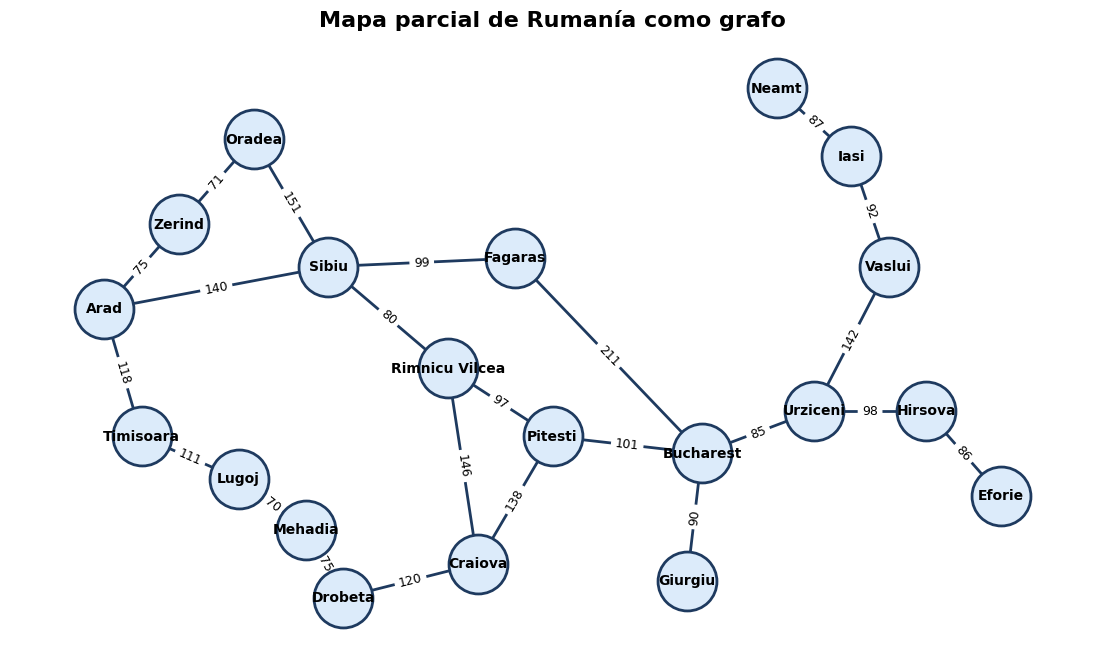

In [ ]:
# networkx es una biblioteca de Python que permite crear, manipular y visualizar grafos (nodos, aristas y sus relaciones)
import networkx as nx
import matplotlib.pyplot as plt

# Crear grafo no dirigido
G = nx.Graph()

# Agregar aristas con pesos
for city, neighbors in graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(city, neighbor, weight=cost)

# Posiciones manuales aproximadas para visualizar el mapa parcial
# Coordenadas (x, y) asignadas a cada nodo para definir dónde se dibuja en la visualización del grafo
pos = {
    'Arad': (0, 4),
    'Zerind': (1, 5),
    'Oradea': (2, 6),
    'Sibiu': (3, 4.5),
    'Timisoara': (0.5, 2.5),
    'Lugoj': (1.8, 2),
    'Mehadia': (2.7, 1.4),
    'Drobeta': (3.2, 0.6),
    'Craiova': (5, 1),
    'Rimnicu Vilcea': (4.6, 3.3),
    'Fagaras': (5.5, 4.6),
    'Pitesti': (6, 2.5),
    'Bucharest': (8, 2.3),
    'Giurgiu': (7.8, 0.8),
    'Urziceni': (9.5, 2.8),
    'Hirsova': (11, 2.8),
    'Eforie': (12, 1.8),
    'Vaslui': (10.5, 4.5),
    'Iasi': (10, 5.8),
    'Neamt': (9, 6.6)
}

plt.figure(figsize=(14, 8))

# Dibujar nodos
nx.draw_networkx_nodes(
    G, pos,
    node_size=1800,
    node_color="#DCEBFA",
    edgecolors="#1E3A5F",
    linewidths=2
)

# Dibujar etiquetas de nodos
nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_weight='bold'
)

# Dibujar aristas
nx.draw_networkx_edges(
    G, pos,
    width=2,
    edge_color="#1E3A5F"
)

# Dibujar pesos en las aristas
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Mapa parcial de Rumanía como grafo", fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

In [ ]:
# Heurística: distancia en línea recta hacia Bucharest. Figura 3.16 (Norvig & Russell, 2021)
# Estimación del costo desde el nodo actual hasta el objetivo, usando la distancia en línea recta como aproximación (valores de la Figura 3.16 (Norvig&Russell, 2021))
# En términos generales, los valores de h(n) se obtienen calculando por ejemplo, con coordenadas geográficas latitud/longitud entre cada ciudad y el objetivo
heuristic = {
    'Arad': 366,
    'Bucharest': 0,
    'Craiova': 160,
    'Drobeta': 242,
    'Eforie': 161,
    'Fagaras': 176,
    'Giurgiu': 77,
    'Hirsova': 151,
    'Iasi': 226,
    'Lugoj': 244,
    'Mehadia': 241,
    'Neamt': 234,
    'Oradea': 380,
    'Pitesti': 100,
    'Rimnicu Vilcea': 193,
    'Sibiu': 253,
    'Timisoara': 329,
    'Urziceni': 80,
    'Vaslui': 199,
    'Zerind': 374
}

In [ ]:
# Nodo inicial y objetivo
start = 'Arad'
goal = 'Bucharest'

## Función para reconstruir la búsqueda

In [ ]:
# Recuperar el camino desde el nodo inicial hasta el objetivo siguiendo los nodos padre almacenados durante la búsqueda
def reconstruct_path(came_from, current):
    path = [current] # Inicia en el nodo objetivo para construir la ruta en sentido inverso

    while current in came_from: # Se ejecuta mientras haya un nodo padre existente para el nodo actual
        current = came_from[current]
        path.append(current) # La lista se construye del nodo objetivo hacia el nodo inicio

    path.reverse() # Invierte el orden para obtener la ruta correcta (inicio - objetivo)
    return path

## Implementación del algoritmo A*

In [ ]:
# La biblioteca heapq permite implementar colas de prioridad, utilizadas para seleccionar eficientemente el elemento con menor valor
import heapq

def a_star(graph, start, goal, heuristic):
    # Cola de prioridad: (f(n), ciudad)
    open_list = [] # Para almacenar los nodos de la frontera
    heapq.heappush(open_list, (heuristic[start], start)) # Ordenar por el menor valor de f(n)

    # Diccionario para reconstruir la ruta desde el objetivo hasta el inicio
    came_from = {} # Almacena el nodo padre de cada nodo visitado

    # Costo acumulado real g(n)
    g_cost = {city: float('inf') for city in graph} # Inicializa en infinito para indicar que aun no se ha encontrado un camino
    g_cost[start] = 0 # No hay costo previo

    # Conjunto de nodos ya expandidos para no procesarlos nuevamente
    closed_set = set()

    while open_list:
        # Extraer el nodo con menor f(n)
        # heappop es una función de la biblioteca heapq que extrae el elemento de menor valor de una lista tratada como heap (cola de prioridad).
        current_f, current = heapq.heappop(open_list)

        # Si ya fue expandido, lo saltamos
        if current in closed_set:
            continue

        # Marcar como expandido
        closed_set.add(current)

        # Verificar si llegamos al objetivo
        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, g_cost[current]

        # Expandir vecinos
        for neighbor, cost in graph[current].items():
            tentative_g = g_cost[current] + cost # Calcula el costo acumulado

            # Si encontramos un mejor camino al vecino
            if tentative_g < g_cost[neighbor]: # Compara con el mejor costo conocido para que decida si se mejora la ruta
                came_from[neighbor] = current # Padre
                g_cost[neighbor] = tentative_g # Nuevo costo mínimo
                f_cost = tentative_g + heuristic[neighbor] # Cálculo de f(n) antes de insertar el nodo en la cola de prioridad
                heapq.heappush(open_list, (f_cost, neighbor)) # Se inserta el vecino en la cola de prioridad para su futura exploración

    return None, float('inf')

## Ejecución

In [ ]:
# path y total_cost son las variables que definimos por el return de la funcion que implementa el algoritmo A*
path, total_cost = a_star(graph, start, goal, heuristic)

print("Ruta encontrada:", path)
print("Costo total:", total_cost)

Ruta encontrada: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest']
Costo total: 418


### Visualizar la ruta encontrada y el costo mínimo logrado

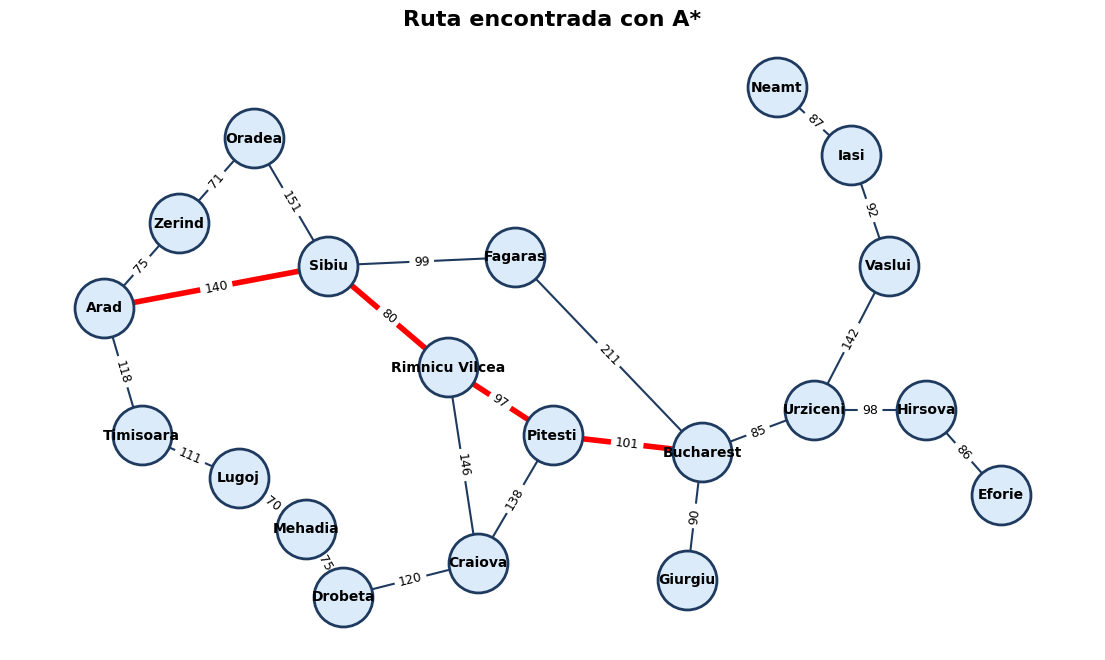

Costo mínimo encontrado: 418


In [ ]:
# Visualizar la ruta encontrada en el grafo

def visualize_path(graph, path):
    import networkx as nx
    import matplotlib.pyplot as plt

    G = nx.Graph()

    # Agregar aristas
    for city, neighbors in graph.items():
        for neighbor, cost in neighbors.items():
            G.add_edge(city, neighbor, weight=cost)

    # Posiciones (mismas que antes)
    pos = {
        'Arad': (0, 4), 'Zerind': (1, 5), 'Oradea': (2, 6),
        'Sibiu': (3, 4.5), 'Timisoara': (0.5, 2.5),
        'Lugoj': (1.8, 2), 'Mehadia': (2.7, 1.4),
        'Drobeta': (3.2, 0.6), 'Craiova': (5, 1),
        'Rimnicu Vilcea': (4.6, 3.3), 'Fagaras': (5.5, 4.6),
        'Pitesti': (6, 2.5), 'Bucharest': (8, 2.3),
        'Giurgiu': (7.8, 0.8), 'Urziceni': (9.5, 2.8),
        'Hirsova': (11, 2.8), 'Eforie': (12, 1.8),
        'Vaslui': (10.5, 4.5), 'Iasi': (10, 5.8), 'Neamt': (9, 6.6)
    }

    # Aristas de la ruta
    path_edges = list(zip(path, path[1:]))

    plt.figure(figsize=(14, 8))

    # Dibujar nodos
    nx.draw_networkx_nodes(G, pos, node_size=1800,
                           node_color="#DCEBFA",
                           edgecolors="#1E3A5F", linewidths=2)

    # Dibujar aristas normales
    nx.draw_networkx_edges(G, pos, width=1.5, edge_color="#1E3A5F")

    # Resaltar ruta
    nx.draw_networkx_edges(G, pos,
                           edgelist=path_edges,
                           width=4,
                           edge_color="red")

    # Etiquetas
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

    edge_labels = nx.get_edge_attributes(G, 'weight')
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)

    plt.title("Ruta encontrada con A*", fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()


# Ejecutar visualización
visualize_path(graph, path)

# Mostrar costo mínimo
print("Costo mínimo encontrado:", total_cost)

## Explicación

In [ ]:
print("A* combina:")
print("- g(n): costo real acumulado desde el inicio")
print("- h(n): estimación del costo restante hasta el objetivo")
print("- f(n) = g(n) + h(n)")
print()
print("En cada paso, A* expande el nodo con menor valor de f(n).")

A* combina:
- g(n): costo real acumulado desde el inicio
- h(n): estimación del costo restante hasta el objetivo
- f(n) = g(n) + h(n)

En cada paso, A* expande el nodo con menor valor de f(n).


## Preguntas para responder

1. ¿Qué rol cumple g(n) dentro de A*?
2. ¿Qué rol cumple h(n)?
3. ¿Por qué A* no elige solo la ciudad con menor heurística?
4. ¿Qué ocurriría si todas las heurísticas fueran 0?
5. ¿Por qué la ruta hallada no siempre pasa por la ciudad aparentemente más cercana al objetivo?

#1. ¿Qué rol cumple g(n) dentro de A*?
$g(n)$ representa el costo real acumulado desde el estado inicial hasta el estado o nodo actual (hasta donde avanzo), su funcion es mostrar cuanto ha costado llegar hasta ese punto del camino.


#2. ¿Qué rol cumple h(n)?
$h(n)$ representa una estimación del costo restante o costo que falta recorrer desde el nodo actual hasta el objetivo.


#3. ¿Por qué A* no elige solo la ciudad con menor heurística?
A* no elige solo la ciudad con menor heuristica porque no usa unicamente $h(n)$, sino la función de evaluacion $f(n)=g(n)+h(n)$. Si eligiera solo la menor heuristica estaría funcionando como Best-First Search. En cambio el algoritmo A* combina el costo real recorrido con el costo estimado restante para elegir el nodo con menor costo total estimado.

#4. ¿Qué ocurriría si todas las heurísticas fueran 0?

Si todas las heurísticas fueran 0, la función de evaluación sería $f(n) = g(n) + 0$. Esto transformaría esencialmente a A* en el Algoritmo de Dijkstra (o Búsqueda de Costo Uniforme) , el cual encontraría la ruta óptima garantizada pero de forma mucho menos eficiente al expandirse en todas direcciones sin una "guía" hacia el objetivo.

#5. ¿Por qué la ruta hallada no siempre pasa por la ciudad aparentemente más cercana al objetivo?

La ruta hallada no siempre pasa por la ciudad aparentemente más cercana porque esta cercanía visual se basa únicamente en la distancia en línea recta, representada por $h(n)$. En un escenario real, los obstáculos topográficos o el mal estado de las carreteras pueden hacer que llegar a ese punto sea físicamente muy costoso, reflejándose en un valor $g(n)$ alto. Por lo tanto, el algoritmo no toma decisiones basadas solo en la apariencia, sino que equilibra ambos factores para determinar la mejor ruta global.

# Planificación determinista con un entorno de incertidumbre

In [ ]:
import random

def a_star(graph, start, goal, heuristic):
    # Cola de prioridad: (f(n), ciudad)
    open_list = [] # Para almacenar los nodos de la frontera
    heapq.heappush(open_list, (heuristic[start], start)) # Ordenar por el menor valor de f(n)

    # Diccionario para reconstruir la ruta desde el objetivo hasta el inicio
    came_from = {} # Almacena el nodo padre de cada nodo visitado

    # Costo acumulado real g(n)
    g_cost = {city: float('inf') for city in graph} # Inicializa en infinito para indicar que aun no se ha encontrado un camino
    g_cost[start] = 0 # No hay costo previo

    # Conjunto de nodos ya expandidos para no procesarlos nuevamente
    closed_set = set()

    while open_list:
        # Extraer el nodo con menor f(n)
        # heappop es una función de la biblioteca heapq que extrae el elemento de menor valor de una lista tratada como heap (cola de prioridad).
        current_f, current = heapq.heappop(open_list)

        # Si ya fue expandido, lo saltamos
        if current in closed_set:
            continue

        # Marcar como expandido
        closed_set.add(current)

        # Verificar si llegamos al objetivo
        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, g_cost[current]

        # Expandir vecinos
        for neighbor, cost in graph[current].items():
            cost_real = cost + random.choice([-10, 0, 15]) # Introduce variabilidad en el costo de la arista simulando incertidumbre
            tentative_g = g_cost[current] + cost_real # Calcula un costo no determinista


            # Si encontramos un mejor camino al vecino
            if tentative_g < g_cost[neighbor]: # Compara con el mejor costo conocido para que decida si se mejora la ruta
                came_from[neighbor] = current # Padre
                g_cost[neighbor] = tentative_g # Nuevo costo mínimo
                f_cost = tentative_g + heuristic[neighbor] # Cálculo de f(n) antes de insertar el nodo en la cola de prioridad
                heapq.heappush(open_list, (f_cost, neighbor)) # Se inserta el vecino en la cola de prioridad para su futura exploración

    return None, float('inf')

## Ejecución con incertidumbre

In [ ]:
# path y total_cost son las variables que definimos por el return de la funcion que implementa el algoritmo A*
path_i, total_cost_i = a_star(graph, start, goal, heuristic)

print("Ruta encontrada:", path_i)
print("Costo total:", total_cost_i)

Ruta encontrada: ['Arad', 'Sibiu', 'Fagaras', 'Bucharest']
Costo total: 430


## Interpretación

Se introdujo incertidumbre en los costos de las aristas mediante variaciones aleatorias, simulando condiciones dinámicas como el tráfico o cambios en el entorno. Esto transforma el problema en un entorno no determinista, donde los costos dejan de ser fijos.

En estas condiciones, el algoritmo A* ya no puede garantizar la optimalidad de la solución, ya que está diseñado para trabajar en entornos deterministas con costos constantes (fijos). Como resultado, al ejecutar el algoritmo varias veces, se pueden obtener diferentes rutas y costos totales. (agregado en la parte final de este colab)

Esto evidencia que, aunque A* es óptimo en escenarios deterministas, su desempeño se ve afectado en presencia de incertidumbre.

##ADICIONAL:
###Agregamos estas lineas de codigo para visualizar mejor la incertidumbre

In [ ]:
for i in range(5):
    path_i, total_cost_i = a_star(graph, start, goal, heuristic)
    print(f"Ejecutación {i+1}:")
    print("Ruta:", path_i)
    print("Costo:", total_cost_i)
    print()

Ejecutación 1:
Ruta: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest']
Costo: 398

Ejecutación 2:
Ruta: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest']
Costo: 423

Ejecutación 3:
Ruta: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest']
Costo: 388

Ejecutación 4:
Ruta: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest']
Costo: 433

Ejecutación 5:
Ruta: ['Arad', 'Sibiu', 'Rimnicu Vilcea', 'Pitesti', 'Bucharest']
Costo: 463

